In [1]:

# CCA 3 - Computer Vision Assignment
# Step 1: Install Required Libraries

!pip install -q scikit-image ultralytics

print("Libraries installation completed!")


Libraries installation completed!


In [2]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd

from skimage.feature import hog
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

from google.colab import files
from ultralytics import YOLO

print("OpenCV Version:", cv2.__version__)
print("NumPy Version:", np.__version__)
print("All libraries imported successfully!")

# Check SIFT availability
if hasattr(cv2, 'SIFT_create'):
    print("SIFT is available!")
else:
    print("SIFT is not available. We will install OpenCV contrib.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
OpenCV Version: 4.14.0
NumPy Version: 2.4.6
All libraries imported successfully!
SIFT is available!


In [3]:

# Create project directories

os.makedirs("CCA3_Computer_Vision/inputs", exist_ok=True)
os.makedirs("CCA3_Computer_Vision/outputs", exist_ok=True)

os.makedirs("CCA3_Computer_Vision/outputs/task1", exist_ok=True)
os.makedirs("CCA3_Computer_Vision/outputs/task2", exist_ok=True)
os.makedirs("CCA3_Computer_Vision/outputs/task3", exist_ok=True)
os.makedirs("CCA3_Computer_Vision/outputs/task4", exist_ok=True)

print("Project folders created successfully!")


Project folders created successfully!


In [6]:

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(filename)


Saving photo_original.jpg to photo_original (1).jpg
Saving photo_second.jpg to photo_second.jpg
Saving traffic_video.mp4 to traffic_video (1).mp4

Uploaded files:
photo_original (1).jpg
photo_second.jpg
traffic_video (1).mp4


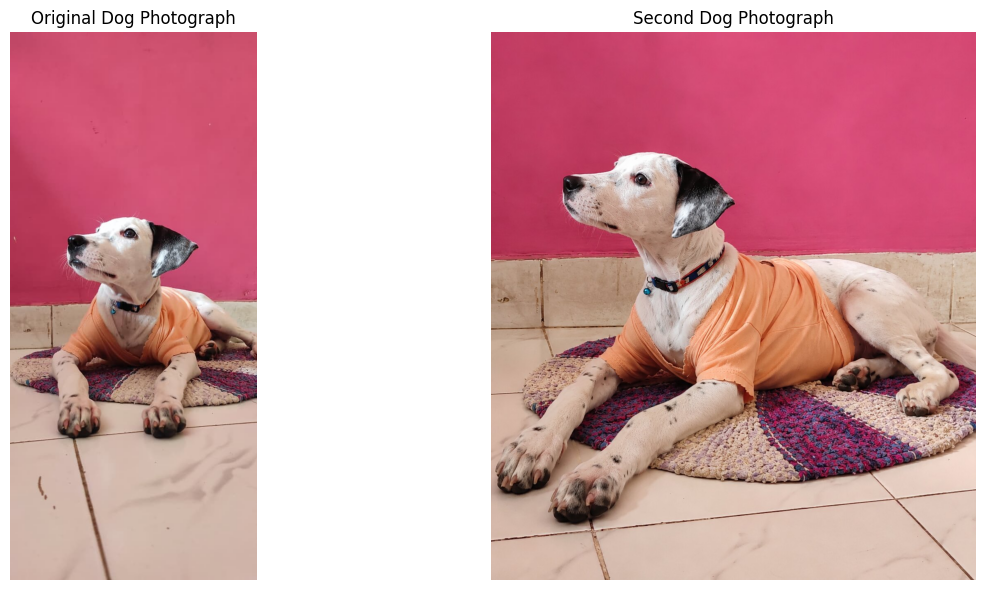

Both photographs loaded successfully!
Original image dimensions: (1160, 522, 3)
Second image dimensions: (1334, 1179, 3)


In [7]:

# TASK 1: Load Original Photographs

import shutil
from PIL import Image

input_folder = "CCA3_Computer_Vision/inputs"
output_folder = "CCA3_Computer_Vision/outputs/task1"

# Select exact uploaded photographs
image1_path = "photo_original.jpg"
image2_path = "photo_second.jpg"

# Check whether both images exist
if not os.path.exists(image1_path):
    raise FileNotFoundError("photo_original.jpg not found!")

if not os.path.exists(image2_path):
    raise FileNotFoundError("photo_second.jpg not found!")

# Copy photographs into project folder
shutil.copy(image1_path, input_folder + "/photo_original.jpg")
shutil.copy(image2_path, input_folder + "/photo_second.jpg")

# Read images using OpenCV
original = cv2.imread(input_folder + "/photo_original.jpg")
second = cv2.imread(input_folder + "/photo_second.jpg")

if original is None or second is None:
    raise ValueError("Unable to read photographs.")

# Convert BGR to RGB
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
second_rgb = cv2.cvtColor(second, cv2.COLOR_BGR2RGB)

# Display both photographs
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Dog Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(second_rgb)
plt.title("Second Dog Photograph")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Both photographs loaded successfully!")
print("Original image dimensions:", original.shape)
print("Second image dimensions:", second.shape)


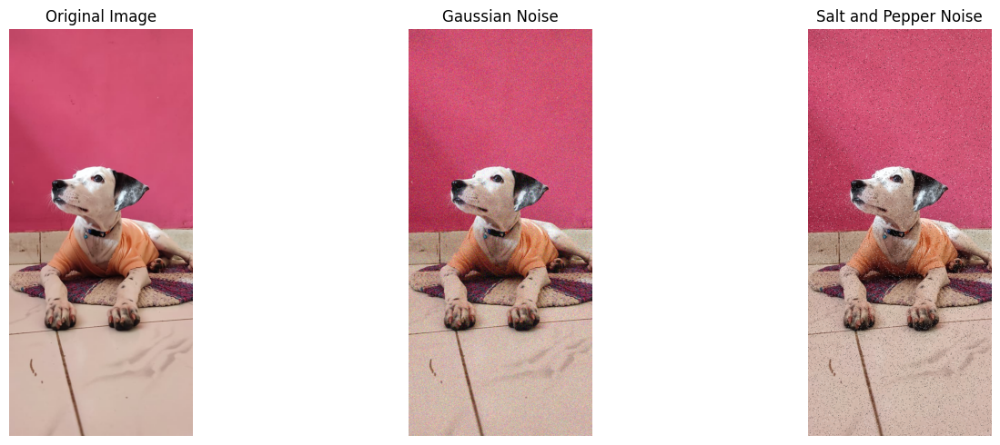

Both noisy images generated and saved!


In [8]:

# Add Gaussian Noise

# Convert image to float
image_float = original_rgb.astype(np.float32)

# Gaussian noise
mean = 0
sigma = 25

gaussian_noise = np.random.normal(
    mean, sigma, original_rgb.shape
)

gaussian_noisy = np.clip(
    image_float + gaussian_noise, 0, 255
).astype(np.uint8)


# Add Salt and Pepper Noise
salt_pepper_noisy = original_rgb.copy()

probability = 0.04
random_values = np.random.random(original_rgb.shape[:2])

salt_pepper_noisy[random_values < probability / 2] = 255
salt_pepper_noisy[random_values > 1 - probability / 2] = 0


# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gaussian_noisy)
plt.title("Gaussian Noise")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(salt_pepper_noisy)
plt.title("Salt and Pepper Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save outputs
cv2.imwrite(
    output_folder + "/gaussian_noisy.jpg",
    cv2.cvtColor(gaussian_noisy, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    output_folder + "/salt_pepper_noisy.jpg",
    cv2.cvtColor(salt_pepper_noisy, cv2.COLOR_RGB2BGR)
)

print("Both noisy images generated and saved!")


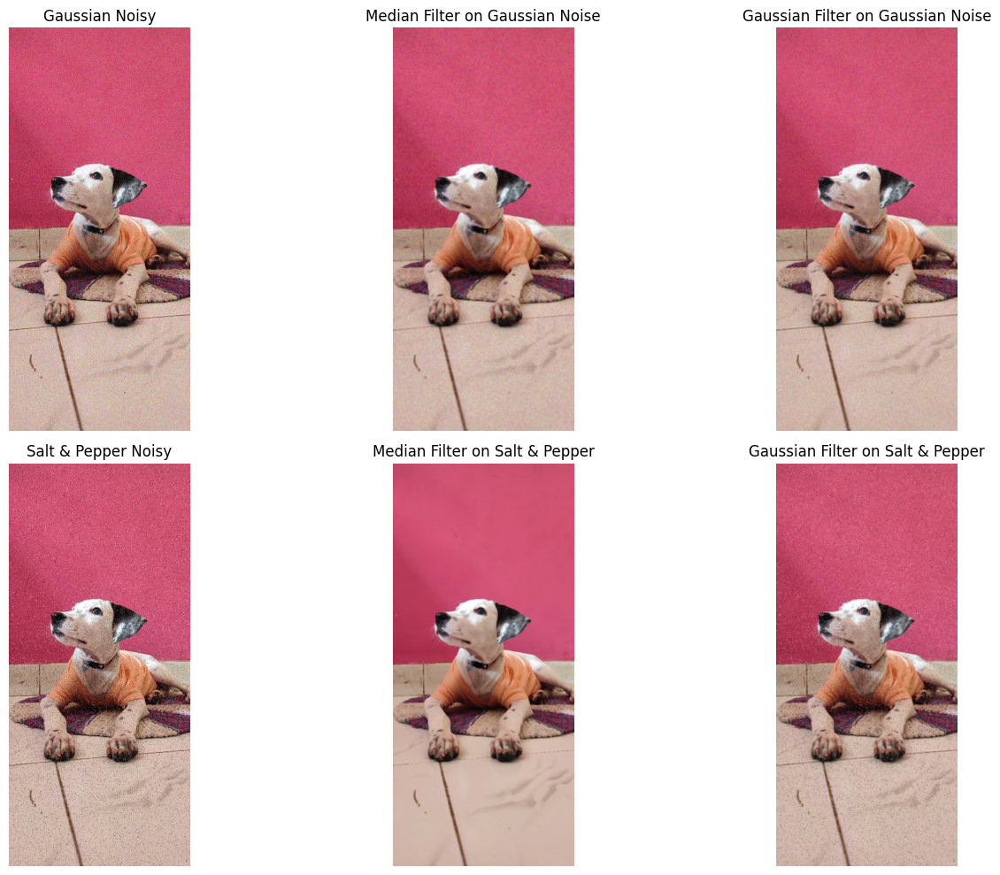

Image restoration completed!


In [9]:

# TASK 1: Image Restoration using Filtering

# Median Filtering
median_gaussian = cv2.medianBlur(gaussian_noisy, 5)
median_salt_pepper = cv2.medianBlur(salt_pepper_noisy, 5)

# Gaussian Filtering
gaussian_filtered_1 = cv2.GaussianBlur(
    gaussian_noisy, (5, 5), 0
)

gaussian_filtered_2 = cv2.GaussianBlur(
    salt_pepper_noisy, (5, 5), 0
)

# Display results
plt.figure(figsize=(15, 10))

images = [
    (gaussian_noisy, "Gaussian Noisy"),
    (median_gaussian, "Median Filter on Gaussian Noise"),
    (gaussian_filtered_1, "Gaussian Filter on Gaussian Noise"),
    (salt_pepper_noisy, "Salt & Pepper Noisy"),
    (median_salt_pepper, "Median Filter on Salt & Pepper"),
    (gaussian_filtered_2, "Gaussian Filter on Salt & Pepper")
]

for i, (img, title) in enumerate(images):
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Save restored images
cv2.imwrite(output_folder + "/median_gaussian.jpg",
            cv2.cvtColor(median_gaussian, cv2.COLOR_RGB2BGR))

cv2.imwrite(output_folder + "/median_salt_pepper.jpg",
            cv2.cvtColor(median_salt_pepper, cv2.COLOR_RGB2BGR))

cv2.imwrite(output_folder + "/gaussian_filtered_gaussian.jpg",
            cv2.cvtColor(gaussian_filtered_1, cv2.COLOR_RGB2BGR))

cv2.imwrite(output_folder + "/gaussian_filtered_salt_pepper.jpg",
            cv2.cvtColor(gaussian_filtered_2, cv2.COLOR_RGB2BGR))

print("Image restoration completed!")


In [10]:

# TASK 1: PSNR and SSIM Calculation

from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

results = []

restored_images = {
    "Gaussian Noise": gaussian_noisy,
    "Median on Gaussian": median_gaussian,
    "Gaussian Filter on Gaussian": gaussian_filtered_1,
    "Salt & Pepper Noise": salt_pepper_noisy,
    "Median on Salt & Pepper": median_salt_pepper,
    "Gaussian Filter on Salt & Pepper": gaussian_filtered_2
}

for name, img in restored_images.items():

    psnr_value = peak_signal_noise_ratio(
        original_rgb, img, data_range=255
    )

    ssim_value = structural_similarity(
        original_rgb, img,
        channel_axis=2,
        data_range=255
    )

    results.append({
        "Technique": name,
        "PSNR (dB)": round(psnr_value, 2),
        "SSIM": round(ssim_value, 4)
    })

# Display comparison table
restoration_df = pd.DataFrame(results)

display(restoration_df)

# Save comparison
restoration_df.to_csv(
    output_folder + "/restoration_metrics.csv",
    index=False
)

print("PSNR and SSIM calculations completed!")


,Technique,PSNR (dB),SSIM
0,Gaussian Noise,20.29,0.1942
1,Median on Gaussian,28.78,0.6899
2,Gaussian Filter on Gaussian,29.49,0.6677
3,Salt & Pepper Noise,19.20,0.3252
4,Median on Salt & Pepper,31.70,0.9420
5,Gaussian Filter on Salt & Pepper,28.57,0.6594


PSNR and SSIM calculations completed!


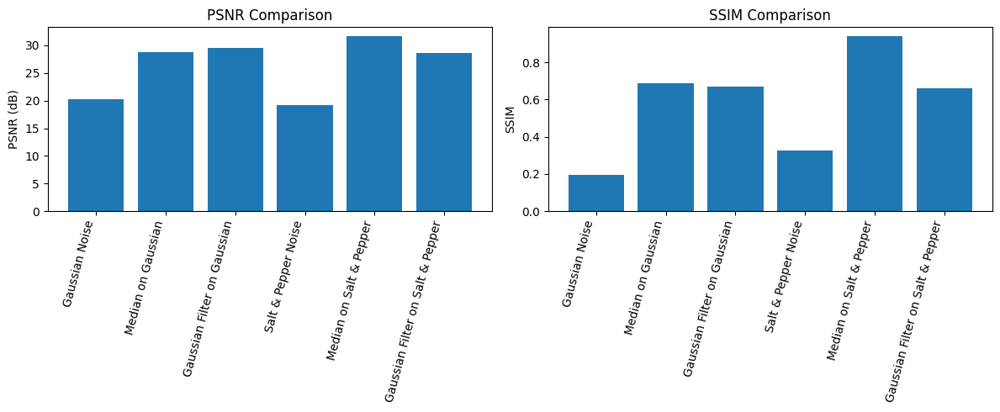

In [11]:

# PSNR and SSIM Comparison Graphs

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.bar(restoration_df["Technique"], restoration_df["PSNR (dB)"])
plt.title("PSNR Comparison")
plt.ylabel("PSNR (dB)")
plt.xticks(rotation=75, ha="right")

plt.subplot(1, 2, 2)
plt.bar(restoration_df["Technique"], restoration_df["SSIM"])
plt.title("SSIM Comparison")
plt.ylabel("SSIM")
plt.xticks(rotation=75, ha="right")

plt.tight_layout()
plt.savefig(output_folder + "/restoration_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()


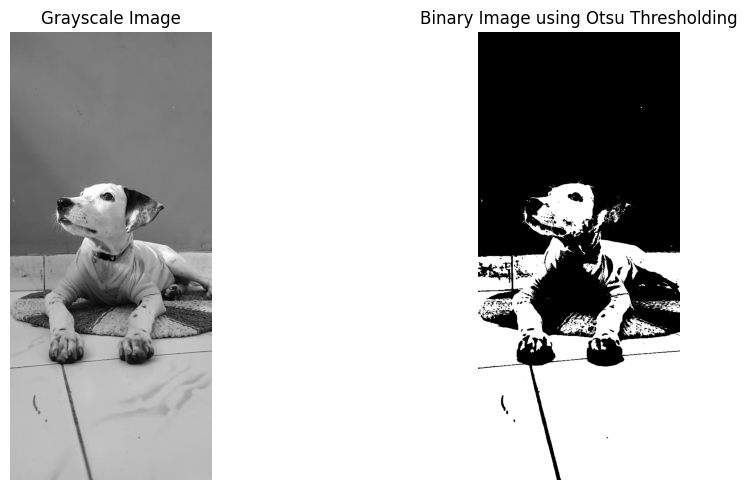

Threshold value: 147.0
Binary thresholding completed!


In [12]:

# Binary Image using Otsu Thresholding

gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

threshold_value, binary_image = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_image, cmap='gray')
plt.title("Binary Image using Otsu Thresholding")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(output_folder + "/binary_image.jpg", binary_image)

print("Threshold value:", threshold_value)
print("Binary thresholding completed!")


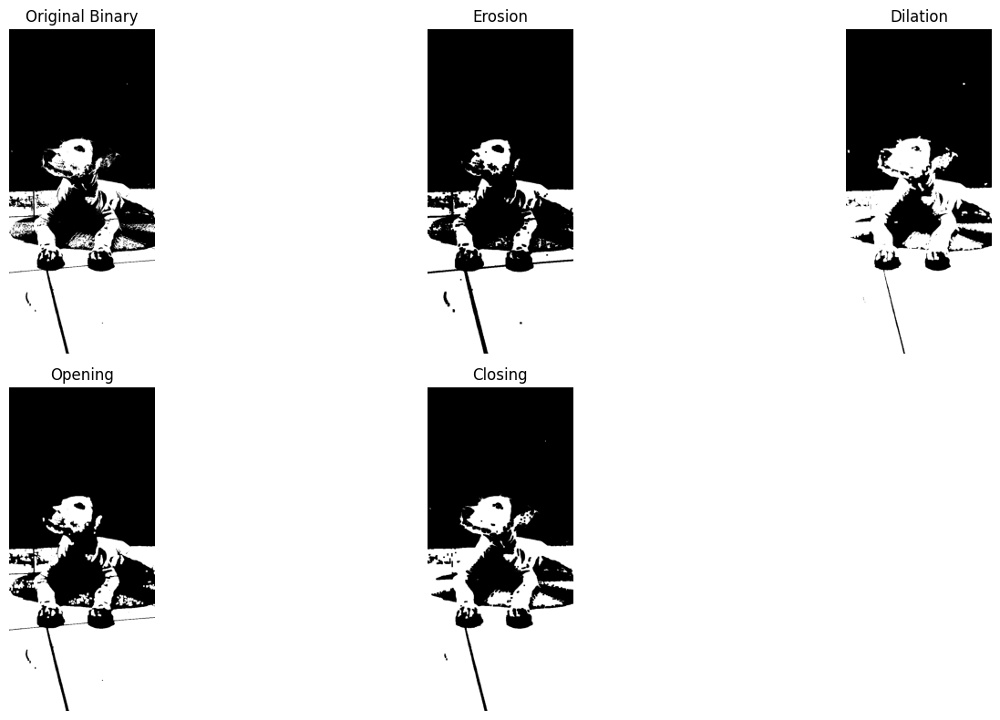

All morphological operations completed!


In [13]:

# Morphological Processing

kernel = np.ones((5, 5), np.uint8)

# Erosion
erosion = cv2.erode(binary_image, kernel, iterations=1)

# Dilation
dilation = cv2.dilate(binary_image, kernel, iterations=1)

# Opening
opening = cv2.morphologyEx(
    binary_image, cv2.MORPH_OPEN, kernel
)

# Closing
closing = cv2.morphologyEx(
    binary_image, cv2.MORPH_CLOSE, kernel
)

# Display all results
morph_images = [
    (binary_image, "Original Binary"),
    (erosion, "Erosion"),
    (dilation, "Dilation"),
    (opening, "Opening"),
    (closing, "Closing")
]

plt.figure(figsize=(15, 8))

for i, (img, title) in enumerate(morph_images):
    plt.subplot(2, 3, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Save outputs
for name, img in [
    ("erosion", erosion),
    ("dilation", dilation),
    ("opening", opening),
    ("closing", closing)
]:
    cv2.imwrite(output_folder + "/" + name + ".jpg", img)

print("All morphological operations completed!")


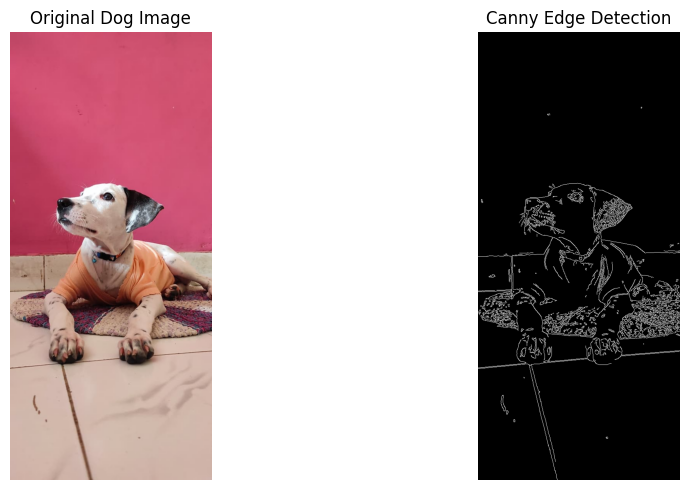

Canny edge detection completed!


In [18]:

# Canny Edge Detection

edges = cv2.Canny(gray, 100, 200)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Dog Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap='gray')
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(output_folder + "/canny_edges.jpg", edges)

print("Canny edge detection completed!")


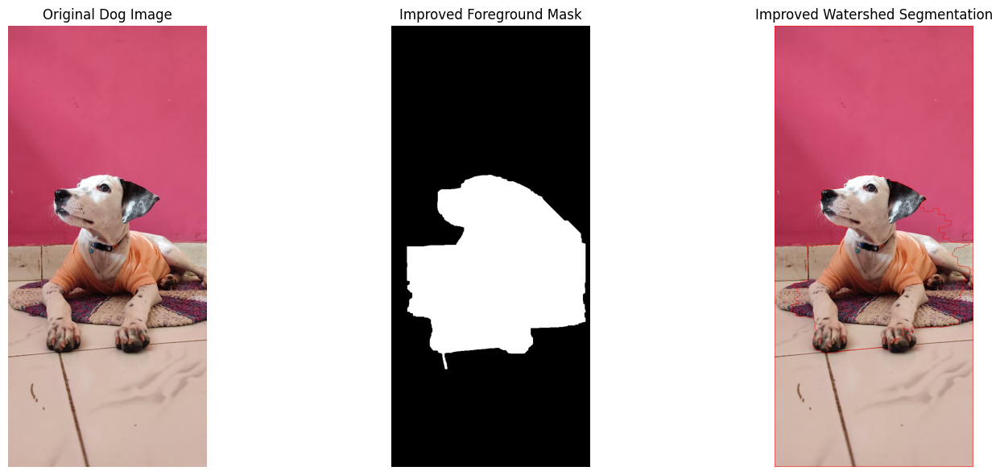

Improved Watershed segmentation completed!
Detected marker regions: 1


In [23]:

# TASK 1: Improved Watershed Segmentation

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load original dog image
image_path = "/content/CCA3_Computer_Vision/inputs/photo_original.jpg"
img = cv2.imread(image_path)

if img is None:
    raise FileNotFoundError("Original image not found!")

original = img.copy()
h, w = img.shape[:2]

# Step 1: Initialize GrabCut
mask = np.zeros((h, w), np.uint8)

# Rectangle covering the dog
rect = (
    int(w * 0.08),
    int(h * 0.30),
    int(w * 0.90),
    int(h * 0.48)
)

bgd_model = np.zeros((1, 65), np.float64)
fgd_model = np.zeros((1, 65), np.float64)

cv2.grabCut(
    img,
    mask,
    rect,
    bgd_model,
    fgd_model,
    7,
    cv2.GC_INIT_WITH_RECT
)

# Step 2: Extract foreground
foreground = np.where(
    (mask == cv2.GC_FGD) |
    (mask == cv2.GC_PR_FGD),
    255, 0
).astype(np.uint8)

# Step 3: Remove small noise
kernel = np.ones((5, 5), np.uint8)

foreground = cv2.morphologyEx(
    foreground,
    cv2.MORPH_OPEN,
    kernel
)

foreground = cv2.morphologyEx(
    foreground,
    cv2.MORPH_CLOSE,
    kernel,
    iterations=2
)

# Step 4: Create sure background
sure_bg = cv2.dilate(
    foreground,
    kernel,
    iterations=3
)

# Step 5: Create sure foreground
dist_transform = cv2.distanceTransform(
    foreground,
    cv2.DIST_L2,
    5
)

_, sure_fg = cv2.threshold(
    dist_transform,
    0.30 * dist_transform.max(),
    255,
    0
)

sure_fg = np.uint8(sure_fg)

# Step 6: Find unknown region
unknown = cv2.subtract(
    sure_bg,
    sure_fg
)

# Step 7: Create markers
num_labels, markers = cv2.connectedComponents(
    sure_fg
)

markers = markers + 1
markers[unknown == 255] = 0

# Step 8: Apply Watershed
markers = cv2.watershed(img, markers)

# Step 9: Highlight segmentation boundaries
result = original.copy()
result[markers == -1] = [0, 0, 255]

# Step 10: Display results
plt.figure(figsize=(16, 6))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
plt.title("Original Dog Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(foreground, cmap="gray")
plt.title("Improved Foreground Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Improved Watershed Segmentation")
plt.axis("off")

plt.tight_layout()
plt.savefig(
    "CCA3_Computer_Vision/outputs/watershed_improved.jpg"
)
plt.show()

print("Improved Watershed segmentation completed!")
print("Detected marker regions:", num_labels - 1)


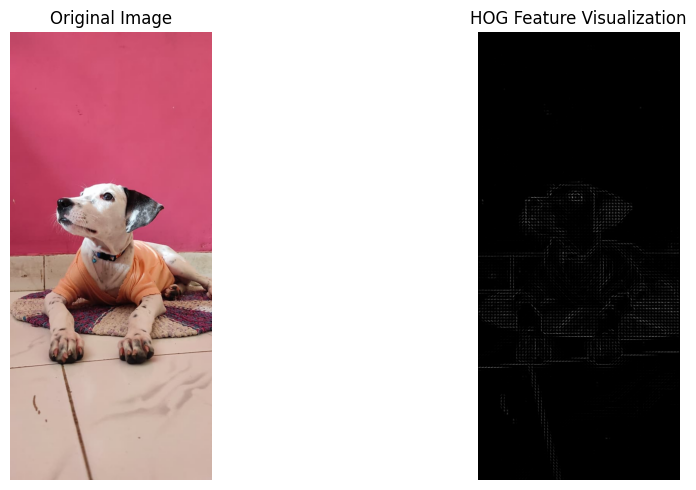

HOG Feature Extraction Completed!
Total HOG features: 331776


In [24]:

# TASK 2: HOG Feature Extraction

from skimage.feature import hog

# Convert original image to grayscale
gray_hog = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

# Extract HOG features
hog_features, hog_image = hog(
    gray_hog,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True,
    block_norm='L2-Hys'
)

# Display original and HOG visualization
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_image, cmap='gray')
plt.title("HOG Feature Visualization")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save HOG output
plt.imsave(
    output_folder.replace("task1", "task2") + "/hog_visualization.png",
    hog_image,
    cmap='gray'
)

print("HOG Feature Extraction Completed!")
print("Total HOG features:", len(hog_features))


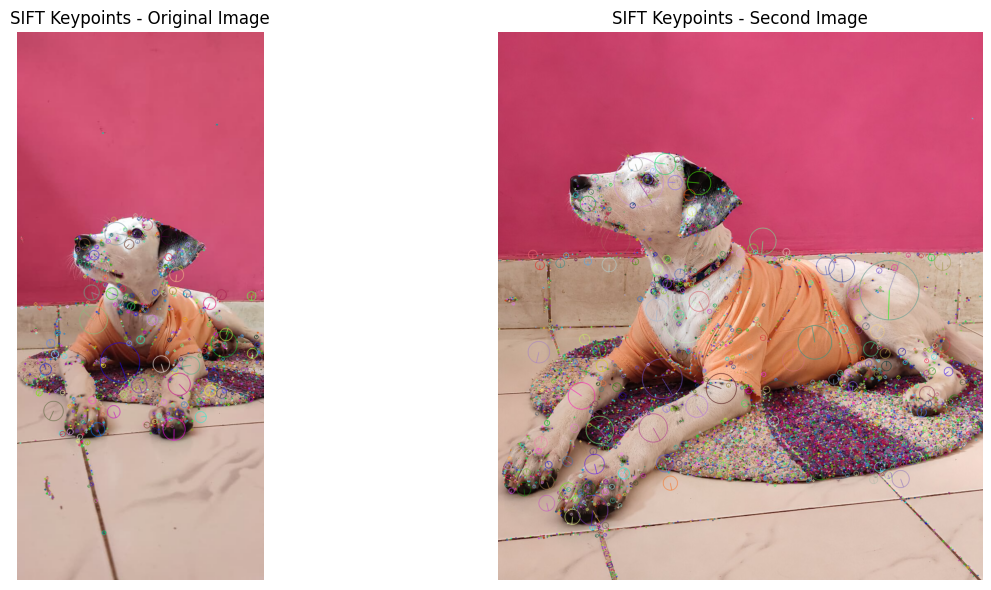

SIFT Keypoint Detection Completed!
Keypoints in Image 1: 1294
Keypoints in Image 2: 6682
Descriptor shape: (1294, 128)


In [25]:

# TASK 2: SIFT Keypoint Detection

# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and descriptors
keypoints1, descriptors1 = sift.detectAndCompute(
    original, None
)

keypoints2, descriptors2 = sift.detectAndCompute(
    second, None
)

# Draw keypoints
sift_image1 = cv2.drawKeypoints(
    original,
    keypoints1,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

sift_image2 = cv2.drawKeypoints(
    second,
    keypoints2,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Display results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(sift_image1, cv2.COLOR_BGR2RGB))
plt.title("SIFT Keypoints - Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(sift_image2, cv2.COLOR_BGR2RGB))
plt.title("SIFT Keypoints - Second Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save results
cv2.imwrite(
    "CCA3_Computer_Vision/outputs/task2/sift_keypoints_1.jpg",
    sift_image1
)

cv2.imwrite(
    "CCA3_Computer_Vision/outputs/task2/sift_keypoints_2.jpg",
    sift_image2
)

print("SIFT Keypoint Detection Completed!")
print("Keypoints in Image 1:", len(keypoints1))
print("Keypoints in Image 2:", len(keypoints2))
print("Descriptor shape:", descriptors1.shape if descriptors1 is not None else None)


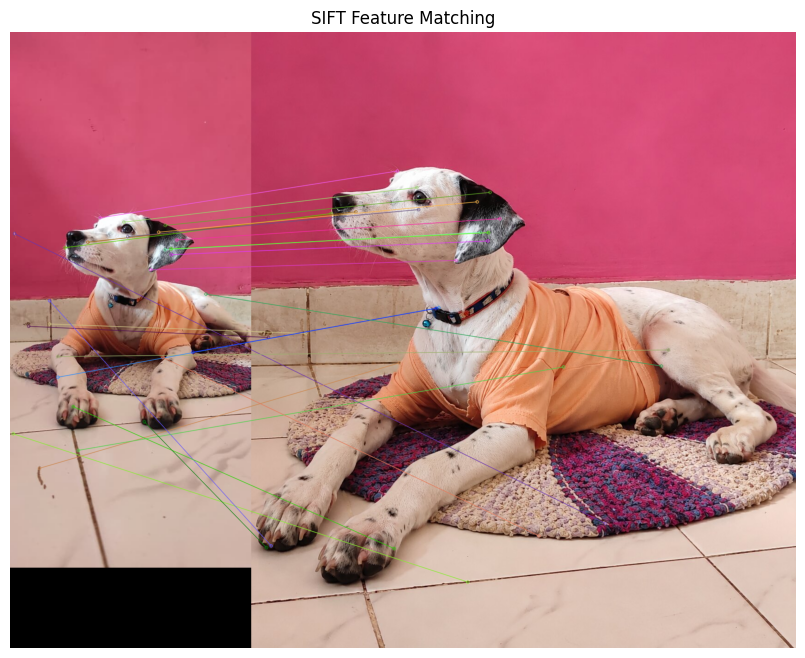

Total initial matches: 1294
Good matches after ratio test: 26


In [26]:

# TASK 2: SIFT Feature Matching

# Check descriptors
if descriptors1 is None or descriptors2 is None:
    raise ValueError("SIFT descriptors not found in one of the images.")

# Create Brute Force Matcher
bf = cv2.BFMatcher()

# Find nearest two matches
matches = bf.knnMatch(
    descriptors1,
    descriptors2,
    k=2
)

# Apply Lowe's Ratio Test
good_matches = []

for pair in matches:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

# Draw matching features
matching_image = cv2.drawMatches(
    original, keypoints1,
    second, keypoints2,
    good_matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(matching_image, cv2.COLOR_BGR2RGB))
plt.title("SIFT Feature Matching")
plt.axis("off")
plt.show()

# Save matching output
cv2.imwrite(
    "CCA3_Computer_Vision/outputs/task2/sift_matching.jpg",
    matching_image
)

print("Total initial matches:", len(matches))
print("Good matches after ratio test:", len(good_matches))


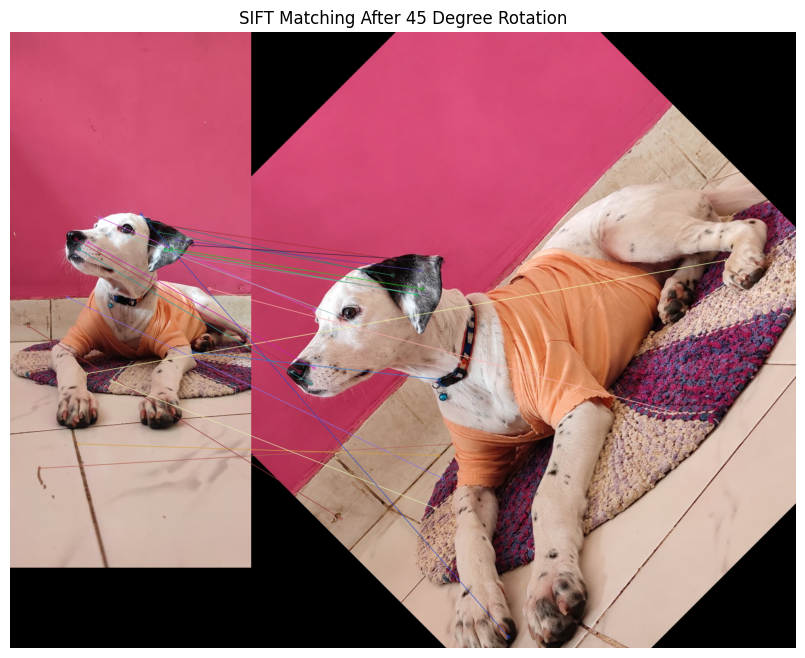

Good matches after rotation: 22


In [27]:

# TASK 2: SIFT Matching After Rotation

h, w = second.shape[:2]

center = (w // 2, h // 2)

rotation_matrix = cv2.getRotationMatrix2D(
    center, 45, 1.0
)

rotated_image = cv2.warpAffine(
    second,
    rotation_matrix,
    (w, h)
)

# Detect SIFT features in rotated image
rotated_keypoints, rotated_descriptors = sift.detectAndCompute(
    rotated_image, None
)

if rotated_descriptors is None:
    raise ValueError("No SIFT descriptors found in rotated image.")

# Match features
rotated_matches = bf.knnMatch(
    descriptors1,
    rotated_descriptors,
    k=2
)

good_rotated_matches = []

for pair in rotated_matches:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.75 * n.distance:
            good_rotated_matches.append(m)

# Draw matches
rotation_result = cv2.drawMatches(
    original, keypoints1,
    rotated_image, rotated_keypoints,
    good_rotated_matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(rotation_result, cv2.COLOR_BGR2RGB))
plt.title("SIFT Matching After 45 Degree Rotation")
plt.axis("off")
plt.show()

cv2.imwrite(
    "CCA3_Computer_Vision/outputs/task2/rotated_matching.jpg",
    rotation_result
)

print("Good matches after rotation:", len(good_rotated_matches))


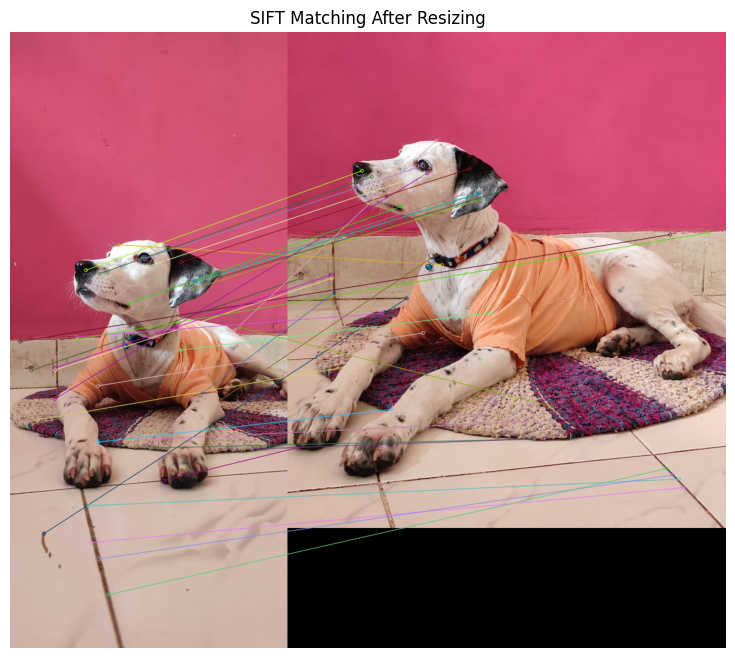

Good matches after resizing: 36


In [28]:

# TASK 2: SIFT Matching After Resizing

resized_image = cv2.resize(
    second,
    None,
    fx=0.7,
    fy=0.7,
    interpolation=cv2.INTER_AREA
)

# Detect SIFT features
resized_keypoints, resized_descriptors = sift.detectAndCompute(
    resized_image, None
)

if resized_descriptors is None:
    raise ValueError("No SIFT descriptors found in resized image.")

# Match features
resized_matches = bf.knnMatch(
    descriptors1,
    resized_descriptors,
    k=2
)

good_resized_matches = []

for pair in resized_matches:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.75 * n.distance:
            good_resized_matches.append(m)

# Draw matches
resize_result = cv2.drawMatches(
    original, keypoints1,
    resized_image, resized_keypoints,
    good_resized_matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(resize_result, cv2.COLOR_BGR2RGB))
plt.title("SIFT Matching After Resizing")
plt.axis("off")
plt.show()

cv2.imwrite(
    "CCA3_Computer_Vision/outputs/task2/resized_matching.jpg",
    resize_result
)

print("Good matches after resizing:", len(good_resized_matches))


,Experiment,Good Matches
0,Original Matching,26
1,After 45 Degree Rotation,22
2,After 70% Resizing,36


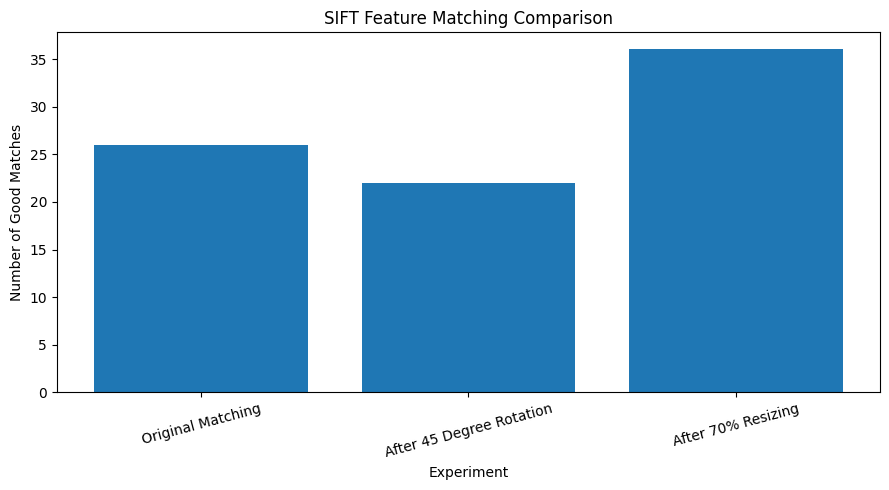

Feature extraction and matching completed!


In [29]:

# Feature Matching Comparison

comparison = pd.DataFrame({
    "Experiment": [
        "Original Matching",
        "After 45 Degree Rotation",
        "After 70% Resizing"
    ],
    "Good Matches": [
        len(good_matches),
        len(good_rotated_matches),
        len(good_resized_matches)
    ]
})

display(comparison)

plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Experiment"],
    comparison["Good Matches"]
)

plt.title("SIFT Feature Matching Comparison")
plt.xlabel("Experiment")
plt.ylabel("Number of Good Matches")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    "CCA3_Computer_Vision/outputs/task2/matching_comparison.png",
    dpi=150
)

plt.show()

comparison.to_csv(
    "CCA3_Computer_Vision/outputs/task2/matching_comparison.csv",
    index=False
)

print("Feature extraction and matching completed!")


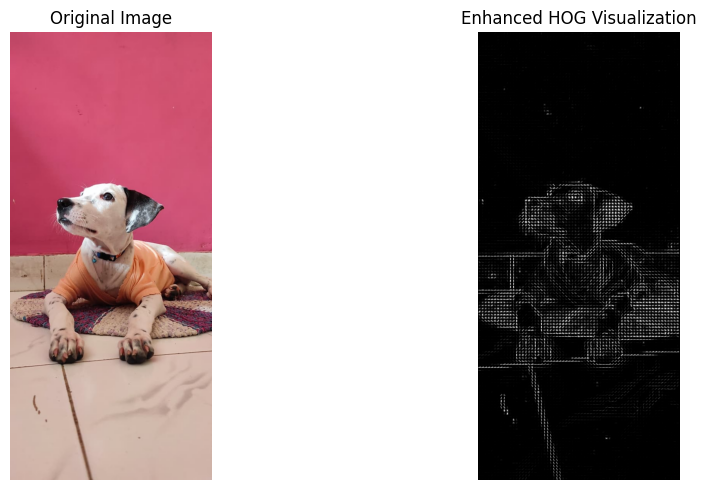

In [30]:

from skimage import exposure

# Improve HOG visualization contrast
hog_image_rescaled = exposure.rescale_intensity(
    hog_image,
    in_range=(0, np.percentile(hog_image, 99))
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_image_rescaled, cmap="gray")
plt.title("Enhanced HOG Visualization")
plt.axis("off")

plt.tight_layout()
plt.show()

plt.imsave(
    "CCA3_Computer_Vision/outputs/task2/hog_visualization.png",
    hog_image_rescaled,
    cmap="gray"
)


Video loaded successfully!
FPS: 25.0
Total Frames: 782
Resolution: 1280 x 720
Duration: 31.28 seconds


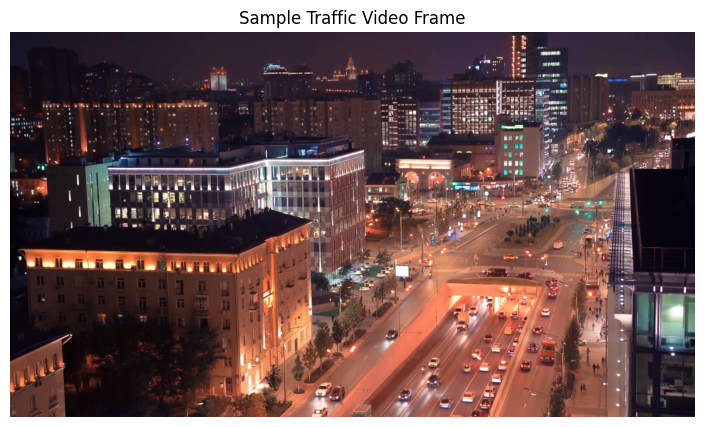

In [31]:

# TASK 3: Load Traffic Video

video_path = "traffic_video.mp4"

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("Unable to open traffic video. Check the filename.")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = total_frames / fps

print("Video loaded successfully!")
print("FPS:", fps)
print("Total Frames:", total_frames)
print("Resolution:", width, "x", height)
print("Duration:", round(duration, 2), "seconds")

# Extract one sample frame
cap.set(cv2.CAP_PROP_POS_MSEC, 3000)
ret, sample_frame = cap.read()

if ret:
    plt.figure(figsize=(10, 5))
    plt.imshow(cv2.cvtColor(sample_frame, cv2.COLOR_BGR2RGB))
    plt.title("Sample Traffic Video Frame")
    plt.axis("off")
    plt.show()

cap.release()


Saving img.jpg to img.jpg


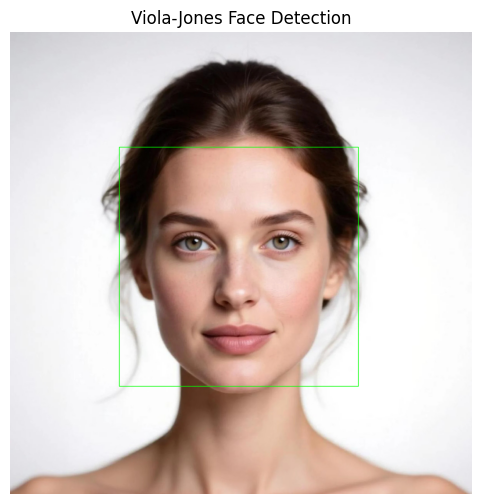

Faces detected: 1
Viola-Jones detection completed!


In [32]:

# TASK 3: Viola-Jones Face Detection

from google.colab import files

face_upload = files.upload()

face_filename = next(iter(face_upload.keys()))

face_image = cv2.imread(face_filename)

if face_image is None:
    raise ValueError("Unable to load face image.")

gray_face = cv2.cvtColor(
    face_image, cv2.COLOR_BGR2GRAY
)

# Load pretrained Haar Cascade
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

# Detect faces
faces = face_cascade.detectMultiScale(
    gray_face,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

# Draw bounding boxes
face_result = face_image.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        face_result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(face_result, cv2.COLOR_BGR2RGB))
plt.title("Viola-Jones Face Detection")
plt.axis("off")
plt.show()

cv2.imwrite(
    "CCA3_Computer_Vision/outputs/task3/haar_face_detection.jpg",
    face_result
)

print("Faces detected:", len(faces))
print("Viola-Jones detection completed!")


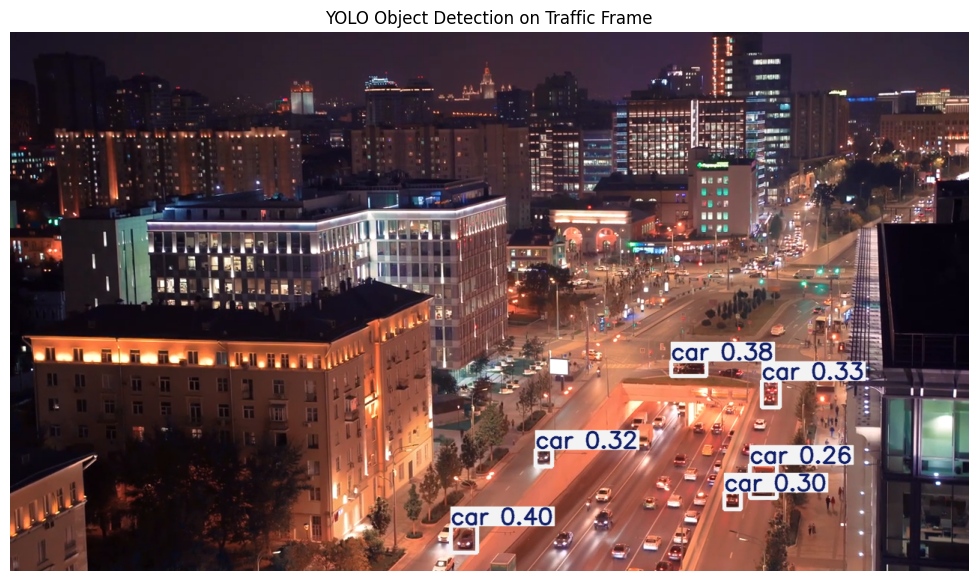

Object: car | Confidence: 0.399
Object: car | Confidence: 0.383
Object: car | Confidence: 0.334
Object: car | Confidence: 0.317
Object: car | Confidence: 0.303
Object: car | Confidence: 0.257
YOLO detection completed!


In [33]:

# TASK 3: YOLO Object Detection

# Load pretrained YOLOv8 model
model = YOLO("yolov8n.pt")

# Detect objects in sample traffic frame
results = model.predict(
    source=sample_frame,
    conf=0.25,
    verbose=False
)

# Get annotated image
yolo_result = results[0].plot()

# Display output
plt.figure(figsize=(14, 7))
plt.imshow(cv2.cvtColor(yolo_result, cv2.COLOR_BGR2RGB))
plt.title("YOLO Object Detection on Traffic Frame")
plt.axis("off")
plt.show()

# Save result
cv2.imwrite(
    "CCA3_Computer_Vision/outputs/task3/yolo_detection.jpg",
    yolo_result
)

# Print detected objects
for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        "Object:", model.names[class_id],
        "| Confidence:", round(confidence, 3)
    )

print("YOLO detection completed!")


In [34]:

# Comparison of Viola-Jones and YOLO

detection_comparison = pd.DataFrame({
    "Algorithm": [
        "Viola-Jones (Haar Cascade)",
        "YOLOv8"
    ],
    "Detection Target": [
        "Human Faces",
        "Multiple Objects and Vehicles"
    ],
    "Detected Objects": [
        len(faces),
        len(results[0].boxes)
    ],
    "Method": [
        "Traditional Machine Learning",
        "Deep Learning"
    ]
})

display(detection_comparison)

detection_comparison.to_csv(
    "CCA3_Computer_Vision/outputs/task3/detection_comparison.csv",
    index=False
)

print("Object detection comparison completed!")


,Algorithm,Detection Target,Detected Objects,Method
0,Viola-Jones (Haar Cascade),Human Faces,1,Traditional Machine Learning
1,YOLOv8,Multiple Objects and Vehicles,6,Deep Learning


Object detection comparison completed!


Total extracted frames: 780


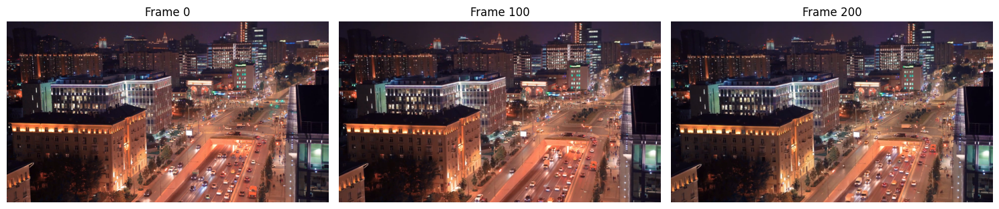

Frame extraction completed!


In [35]:

# TASK 4: Extract Video Frames

cap = cv2.VideoCapture(video_path)

frames = []

while True:
    ret, frame = cap.read()

    if not ret:
        break

    # Resize for faster processing
    frame = cv2.resize(frame, (640, 360))
    frames.append(frame)

cap.release()

print("Total extracted frames:", len(frames))

# Display selected frames
plt.figure(figsize=(15, 5))

for i, index in enumerate([0, 100, 200]):
    if index < len(frames):
        plt.subplot(1, 3, i + 1)
        plt.imshow(
            cv2.cvtColor(frames[index], cv2.COLOR_BGR2RGB)
        )
        plt.title(f"Frame {index}")
        plt.axis("off")

plt.tight_layout()
plt.show()

print("Frame extraction completed!")


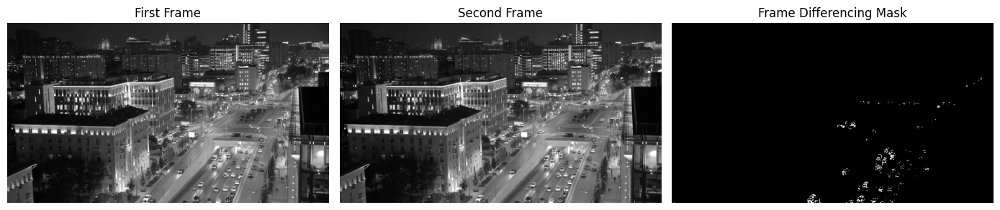

Frame differencing completed!


In [36]:

# TASK 4: Frame Differencing

gray_frames = [
    cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    for frame in frames
]

# Select consecutive frames
frame1 = gray_frames[100]
frame2 = gray_frames[101]

# Calculate absolute difference
difference = cv2.absdiff(frame1, frame2)

# Apply threshold
_, foreground_mask = cv2.threshold(
    difference, 25, 255, cv2.THRESH_BINARY
)

# Display results
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(frame1, cmap="gray")
plt.title("First Frame")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(frame2, cmap="gray")
plt.title("Second Frame")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(foreground_mask, cmap="gray")
plt.title("Frame Differencing Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    "CCA3_Computer_Vision/outputs/task4/frame_difference.jpg",
    foreground_mask
)

print("Frame differencing completed!")


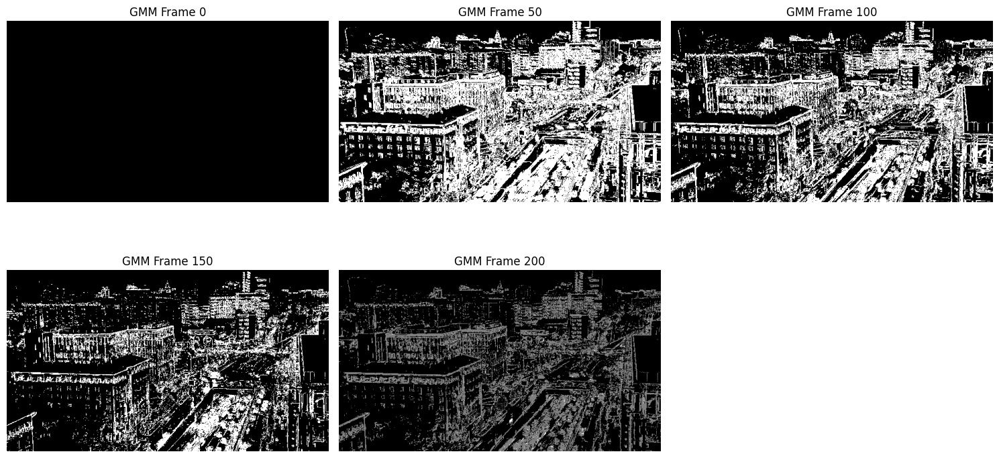

GMM Background Subtraction completed!


In [37]:

# TASK 4: GMM Background Subtraction

# Create MOG2 background subtractor
background_subtractor = cv2.createBackgroundSubtractorMOG2(
    history=500,
    varThreshold=25,
    detectShadows=True
)

# Process selected video frames
selected_indices = [0, 50, 100, 150, 200]

plt.figure(figsize=(15, 8))

for i, index in enumerate(selected_indices):
    foreground = background_subtractor.apply(frames[index])

    plt.subplot(2, 3, i + 1)
    plt.imshow(foreground, cmap="gray")
    plt.title(f"GMM Frame {index}")
    plt.axis("off")

# Save final foreground mask
cv2.imwrite(
    "CCA3_Computer_Vision/outputs/task4/gmm_background_subtraction.jpg",
    foreground
)

plt.tight_layout()
plt.show()

print("GMM Background Subtraction completed!")


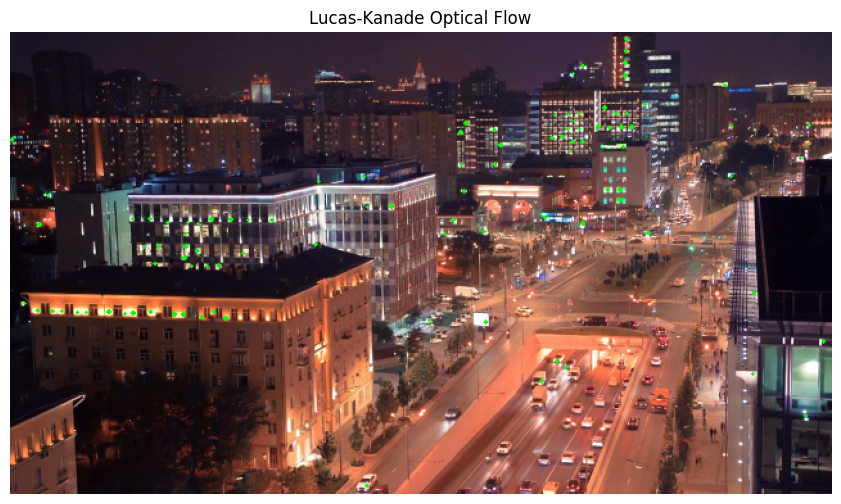

Initial feature points: 100
Successfully tracked points: 100
Lucas-Kanade Optical Flow completed!


In [38]:

# TASK 4: Lucas-Kanade Optical Flow

# Select two consecutive frames
old_gray = gray_frames[100]
new_gray = gray_frames[101]

# Detect good feature points
feature_params = dict(
    maxCorners=100,
    qualityLevel=0.3,
    minDistance=7,
    blockSize=7
)

p0 = cv2.goodFeaturesToTrack(
    old_gray,
    mask=None,
    **feature_params
)

# Lucas-Kanade parameters
lk_params = dict(
    winSize=(15, 15),
    maxLevel=2,
    criteria=(
        cv2.TERM_CRITERIA_EPS |
        cv2.TERM_CRITERIA_COUNT,
        10,
        0.03
    )
)

# Calculate optical flow
p1, status, error = cv2.calcOpticalFlowPyrLK(
    old_gray,
    new_gray,
    p0,
    None,
    **lk_params
)

# Draw motion vectors
flow_result = frames[101].copy()

good_new = p1[status.flatten() == 1]
good_old = p0[status.flatten() == 1]

for new, old in zip(good_new, good_old):
    a, b = new.ravel().astype(int)
    c, d = old.ravel().astype(int)

    cv2.arrowedLine(
        flow_result,
        (c, d),
        (a, b),
        (0, 255, 0),
        2,
        tipLength=0.3
    )

plt.figure(figsize=(12, 6))
plt.imshow(
    cv2.cvtColor(flow_result, cv2.COLOR_BGR2RGB)
)
plt.title("Lucas-Kanade Optical Flow")
plt.axis("off")
plt.show()

cv2.imwrite(
    "CCA3_Computer_Vision/outputs/task4/lucas_kanade_optical_flow.jpg",
    flow_result
)

print("Initial feature points:", len(p0))
print("Successfully tracked points:", len(good_new))
print("Lucas-Kanade Optical Flow completed!")


In [39]:

# FINAL TASK SUMMARY

task_summary = pd.DataFrame({
    "Experiment": [
        "Viola-Jones Face Detection",
        "YOLOv8 Object Detection",
        "Video Frame Extraction",
        "Frame Differencing",
        "GMM Background Subtraction",
        "Lucas-Kanade Optical Flow"
    ],
    "Status": [
        "Completed",
        "Completed",
        "Completed",
        "Completed",
        "Completed",
        "Completed"
    ]
})

display(task_summary)

task_summary.to_csv(
    "CCA3_Computer_Vision/outputs/task4/final_task_summary.csv",
    index=False
)

print("All Computer Vision experiments completed!")


,Experiment,Status
0,Viola-Jones Face Detection,Completed
1,YOLOv8 Object Detection,Completed
2,Video Frame Extraction,Completed
3,Frame Differencing,Completed
4,GMM Background Subtraction,Completed
5,Lucas-Kanade Optical Flow,Completed


All Computer Vision experiments completed!


In [40]:

import shutil
from google.colab import files

shutil.make_archive(
    "CCA3_Computer_Vision_Submission",
    "zip",
    "CCA3_Computer_Vision"
)

files.download("CCA3_Computer_Vision_Submission.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>